# Preview augmentation trên frame video gốc
Ba ảnh cùng frame: **Original / Augment trái / Augment phải**. Ảnh nền giữ nguyên; chỉ keypoint thay đổi.
Đặt `SAMPLE_DIR` và `VIDEO_PATH` nếu muốn chọn video khác. Overlay ảnh dùng `INPUT_MODE="raw"` (tọa độ chuẩn hóa theo ảnh).


In [58]:
from pathlib import Path
import sys, importlib.util, inspect, ast, textwrap, warnings
import numpy as np
import matplotlib.pyplot as plt
import cv2
from functools import lru_cache
from IPython.display import display, HTML

PROJECT_ROOT = Path(r"D:/SignDetection")
sys.path.insert(0, str(PROJECT_ROOT)) if str(PROJECT_ROOT) not in sys.path else None
from config import _COORD_DIM, _N_HAND, _N_POSE, _REMOVE_POSE_IDX

# Load files directly so this viewer does not initialize MediaPipe/app models.
def load_module(name, relative_path):
    spec = importlib.util.spec_from_file_location(name, PROJECT_ROOT / relative_path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module

aug_module = load_module("augmentation_preview", "src/data/augmentation.py")
SkeletonAugmentor = aug_module.SkeletonAugmentor
fusion_module = load_module("fusion_preview", "src/utils/fusion_block.py")

# Warn if the current implementation applies viewpoint augmentation more than once.
tree = ast.parse(textwrap.dedent(inspect.getsource(SkeletonAugmentor.__call__)))
view_calls = sum(isinstance(n, ast.Call) and isinstance(n.func, ast.Attribute)
                 and n.func.attr == "_simulate_viewpoint" for n in ast.walk(tree))
if view_calls > 1:
    warnings.warn(f"__call__ currently has {view_calls} viewpoint calls. Preview reflects that code; shifts may be compounded.")


In [59]:
FEATURE_ROOT = PROJECT_ROOT / "datasets/processed/wlasl_features_0_6"
SAMPLE_DIR = None  # Example: FEATURE_ROOT / "07400"
VIDEO_PATH = None  # Default: datasets/raw/WLASL/videos/<sample_id>.mp4
VIDEO_FRAME_OFFSET = 0  # Set only if saved keypoints were trimmed before extraction.
INPUT_MODE = "raw"  # "raw" or "training"
SEED = 42
SHOULDER_FACTOR = 0.7  # Fixed strengths make the comparison reproducible.
HAND_SHIFT = 0.2     # Fraction of shoulder x-distance.
FRAME_INDEX = None  # Auto-select the frame with the most detected hand nodes.

if SAMPLE_DIR is None:
    # Prefer a sample with visible hands so the first comparison is informative.
    for candidate in sorted(FEATURE_ROOT.iterdir()):
        if not candidate.is_dir() or not all((candidate/f"{key}.npy").is_file() for key in ("pose","left_hand","right_hand")):
            continue
        hands = [np.load(candidate/f"{key}.npy", allow_pickle=False).reshape(-1,21,3)[:,:,:2]
                 for key in ("left_hand","right_hand")]
        if any((np.isfinite(h).all(-1) & np.any(h != 0, axis=-1)).any() for h in hands):
            SAMPLE_DIR = candidate
            break
if SAMPLE_DIR is None:
    raise FileNotFoundError("No landmark sample found. Set SAMPLE_DIR to a directory with pose/left_hand/right_hand.npy")
SAMPLE_DIR = Path(SAMPLE_DIR)
pose = np.load(SAMPLE_DIR / "pose.npy", allow_pickle=False).reshape(-1, 33, 3)[:, :, :_COORD_DIM]
left = np.load(SAMPLE_DIR / "left_hand.npy", allow_pickle=False).reshape(-1, 21, 3)[:, :, :_COORD_DIM]
right = np.load(SAMPLE_DIR / "right_hand.npy", allow_pickle=False).reshape(-1, 21, 3)[:, :, :_COORD_DIM]
assert len(pose) == len(left) == len(right) and len(pose) > 0, "Frame counts must match and be nonempty"
kept_pose = [i for i in range(33) if i not in set(_REMOVE_POSE_IDX)]
assert len(kept_pose) == _N_POSE
original_keypoints = np.concatenate([pose[:, kept_pose], left, right], axis=1).astype(np.float32)
N = _N_POSE + 2 * _N_HAND
if INPUT_MODE == "raw":
    original_features = original_keypoints.reshape(len(pose), -1)
    block_names = ["raw"]
elif INPUT_MODE == "training":
    fusion = fusion_module.FusionComponent()
    original_features = np.concatenate([
        fusion.fuse_follow_shape(pose, left, right),
        fusion.fuse(pose, left, right),
        fusion.fuse_follow_position(pose, left, right),
    ], axis=-1).astype(np.float32)
    block_names = ["shape", "average", "position"]
else:
    raise ValueError("INPUT_MODE must be raw or training")
if FRAME_INDEX is None:
    hand_nodes = original_keypoints[:, _N_POSE:]
    hand_visible = np.isfinite(hand_nodes).all(-1) & np.any(hand_nodes != 0, axis=-1)
    FRAME_INDEX = int(np.argmax(hand_visible.sum(axis=1)))
print("Sample:", SAMPLE_DIR.name, "| mode:", INPUT_MODE)
print("Original keypoints:", original_keypoints.shape, "| augment input:", original_features.shape)

VIDEO_PATH = Path(VIDEO_PATH) if VIDEO_PATH else PROJECT_ROOT / "datasets/raw/WLASL/videos" / f"{SAMPLE_DIR.name}.mp4"
if not VIDEO_PATH.is_file():
    raise FileNotFoundError(f"Video missing: {VIDEO_PATH}. Set VIDEO_PATH to the matching original video.")
cap = cv2.VideoCapture(str(VIDEO_PATH))
if not cap.isOpened():
    raise RuntimeError(f"Cannot open video: {VIDEO_PATH}")
video_frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()
if video_frame_count != len(pose):
    warnings.warn(f"Video has {video_frame_count} frames; keypoints have {len(pose)}. Verify VIDEO_FRAME_OFFSET/frame alignment.")

@lru_cache(maxsize=8)
def original_frame(frame_index):
    cap = cv2.VideoCapture(str(VIDEO_PATH))
    try:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_index) + VIDEO_FRAME_OFFSET)
        ok, bgr = cap.read()
        if not ok:
            raise RuntimeError(f"Cannot read video frame {frame_index + VIDEO_FRAME_OFFSET}")
        return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    finally:
        cap.release()
print("Background video:", VIDEO_PATH)


Sample: 00335 | mode: raw
Original keypoints: (58, 47, 2) | augment input: (58, 94)
Background video: D:\SignDetection\datasets\raw\WLASL\videos\00335.mp4


In [60]:
# Separate generators with the same seed keep any incidental randomness comparable.
def make_augmentor():
    return SkeletonAugmentor(
        shoulder_width_range=(SHOULDER_FACTOR, SHOULDER_FACTOR),
        hand_shift_range=(HAND_SHIFT, HAND_SHIFT),
        rng=np.random.default_rng(SEED),
    )
original_snapshot = original_features.copy()
left_features = make_augmentor()(original_features, view_direction="left")
right_features = make_augmentor()(original_features, view_direction="right")
np.testing.assert_array_equal(original_features, original_snapshot)
sequences = [array.reshape(len(pose), len(block_names), N, _COORD_DIM)
             for array in (original_features, left_features, right_features)]
original_blocks, augmented_left_keypoints, augmented_right_keypoints = sequences
# A zero wrist in shape can still be a visible node in another feature block.
present = np.any(original_blocks != 0, axis=(1, 3)) & np.isfinite(original_blocks).all(axis=(1, 3))
assert all(np.isfinite(array).all() for array in sequences), "Input/output contains NaN or Inf"
print("Output keypoints [T, blocks, nodes, coords]:", augmented_left_keypoints.shape)
print("Original input unchanged; node counts and frame counts preserved.")


Output keypoints [T, blocks, nodes, coords]: (58, 1, 47, 2)
Original input unchanged; node counts and frame counts preserved.


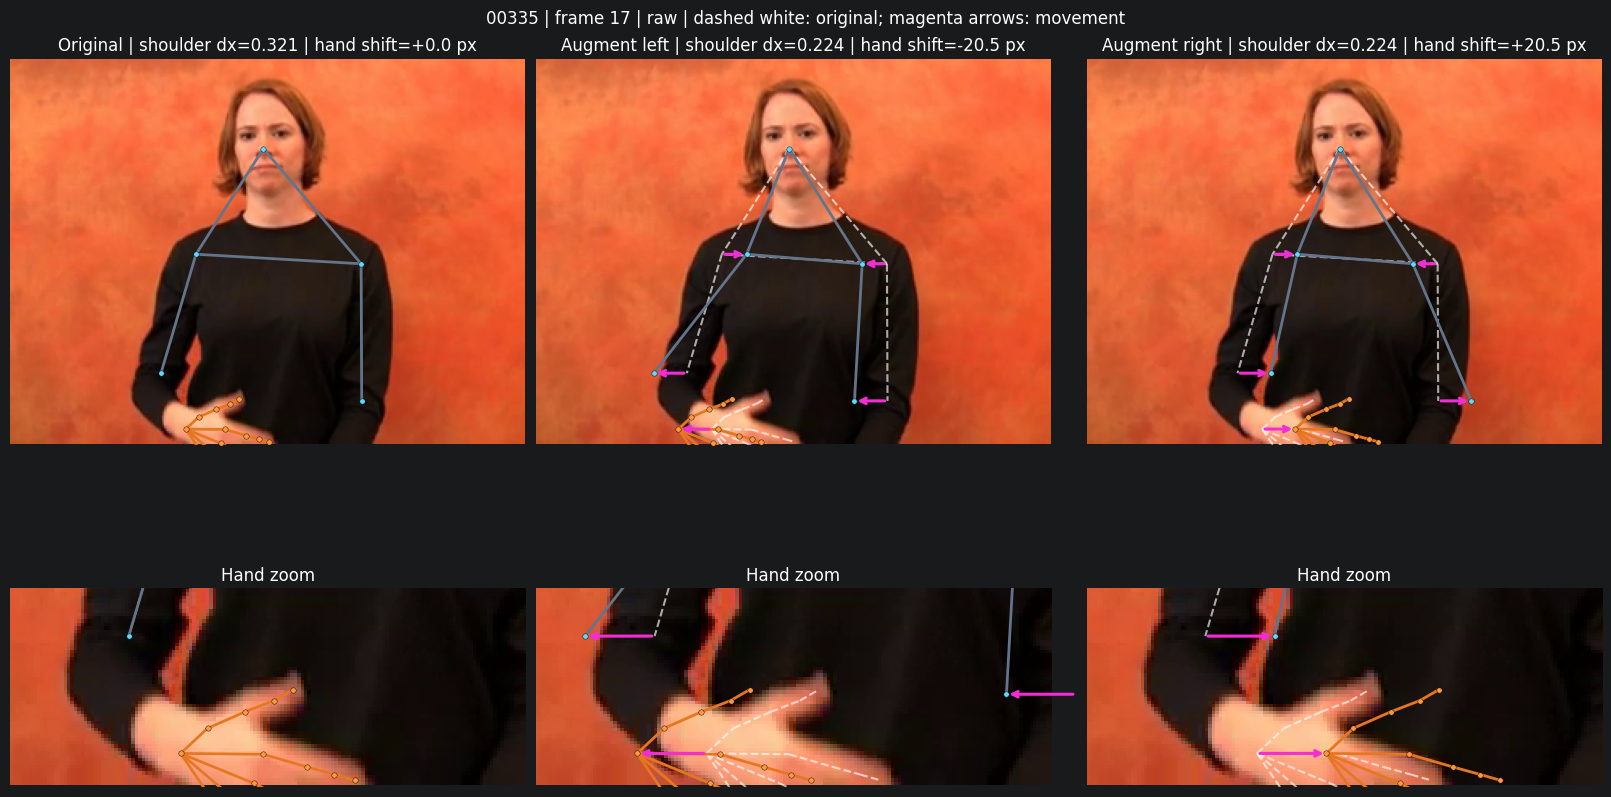

In [61]:
hand_edges = [(0,1),(1,2),(2,3),(3,4),(0,5),(5,6),(6,7),(7,8),
              (0,9),(9,10),(10,11),(11,12),(0,13),(13,14),(14,15),(15,16),
              (0,17),(17,18),(18,19),(19,20)]
pose_map = {old:new for new,old in enumerate(kept_pose)}
pose_edges_raw = [(0,11),(0,12),(11,12),(11,13),(13,15),(12,14),(14,16),
                  (11,23),(12,24),(23,24)]
pose_edges = [(pose_map[a],pose_map[b]) for a,b in pose_edges_raw if a in pose_map and b in pose_map]
edges = [(a,b,"#64748b") for a,b in pose_edges]
edges += [(a+_N_POSE,b+_N_POSE,"#168c71") for a,b in hand_edges]
edges += [(a+_N_POSE+_N_HAND,b+_N_POSE+_N_HAND,"#e67722") for a,b in hand_edges]
ls,rs = pose_map[11],pose_map[12]

def axis_limits(block):
    values = np.concatenate([array[:, block][present] for array in sequences], axis=0)
    values = values[np.isfinite(values).all(axis=1)]
    if not len(values): return (-1,1), (-1,1)
    low,high = values[:,:2].min(0),values[:,:2].max(0)
    padding = max(float(np.max(high-low))*.12, .05)
    return (low[0]-padding,high[0]+padding),(low[1]-padding,high[1]+padding)

def draw_frame(ax, points, mask, title, limits, show_ids=False, frame_index=0):
    points = points.copy()
    if INPUT_MODE == "raw":
        image = original_frame(int(frame_index))
        height,width = image.shape[:2]
        ax.imshow(image)
        points[:,:2] *= np.array([width,height])
    reference = original_blocks[int(frame_index), CURRENT_BLOCK].copy()
    if INPUT_MODE == "raw": reference[:,:2] *= np.array([width,height])
    if "Original" not in title:
        for a,b,_ in edges:
            if mask[a] and mask[b]:
                ax.plot(reference[[a,b],0],reference[[a,b],1],color="white",alpha=.65,
                        linewidth=1.5,linestyle="--",zorder=2)
        for idx in [ls,rs,*[pose_map[n] for n in (13,14) if n in pose_map],_N_POSE,_N_POSE+_N_HAND]:
            if mask[idx]:
                ax.annotate("",xy=points[idx,:2],xytext=reference[idx,:2],
                            arrowprops=dict(arrowstyle="->",color="#f22dd5",lw=2.2),zorder=5)
    for a,b,color in edges:
        if mask[a] and mask[b]:
            ax.plot(points[[a,b],0],points[[a,b],1],color=color,linewidth=2)
    colors = ["#5ed9ff"]*_N_POSE+["#19e6a0"]*_N_HAND+["#ff983d"]*_N_HAND
    for idx in np.flatnonzero(mask):
        ax.scatter(*points[idx,:2],color=colors[idx],s=15,edgecolors="black",linewidths=.3,zorder=3)
        if show_ids:
            ax.annotate(str(idx),points[idx,:2],fontsize=7,color="yellow")
    ax.set_title(title)
    if INPUT_MODE == "raw":
        ax.set_xlim(0,width);ax.set_ylim(height,0);ax.set_aspect("equal");ax.axis("off")
    else:
        ax.set(xlim=limits[0],ylim=limits[1],xlabel="x",ylabel="y")
        ax.invert_yaxis();ax.set_aspect("equal",adjustable="box");ax.grid(alpha=.15)

CURRENT_BLOCK = 0

def view_frame(frame=0, block=0, show_ids=False):
    global CURRENT_BLOCK
    frame=int(frame); block=int(block); CURRENT_BLOCK=block
    if not 0 <= frame < len(pose): raise IndexError("Invalid frame index")
    limits=axis_limits(block)
    rows = 2 if INPUT_MODE == "raw" else 1
    fig,axes=plt.subplots(rows,3,figsize=(16,9 if rows==2 else 5),constrained_layout=True,squeeze=False)
    hand_mask=present[frame,_N_POSE:]
    crop=None
    if rows==2 and hand_mask.any():
        image=original_frame(frame);height,pixel_width=image.shape[:2]
        hand_points=np.concatenate([seq[frame,block,_N_POSE:,:2][hand_mask] for seq in sequences])
        low=hand_points.min(0)*[pixel_width,height];high=hand_points.max(0)*[pixel_width,height]
        pad=max(float(np.max(high-low))*.25,30)
        crop=(max(0,low[0]-pad),min(pixel_width,high[0]+pad),max(0,low[1]-pad),min(height,high[1]+pad))
    for column,(sequence,title) in enumerate(zip(sequences,["Original","Augment left","Augment right"])):
        points=sequence[frame,block]
        width=abs(points[ls,0]-points[rs,0])
        delta=points[_N_POSE:,0]-original_blocks[frame,block,_N_POSE:,0]
        shift=float(np.median(delta[hand_mask])) if hand_mask.any() else 0.0
        unit="coord"
        if INPUT_MODE=="raw": shift*=original_frame(frame).shape[1];unit="px"
        caption=f"{title} | shoulder dx={width:.3f} | hand shift={shift:+.1f} {unit}"
        for row in range(rows):
            draw_frame(axes[row,column],points,present[frame],caption if row==0 else "Hand zoom",limits,show_ids,frame_index=frame)
            if row==1 and crop:
                axes[row,column].set_xlim(crop[:2]);axes[row,column].set_ylim(crop[3],crop[2])
    fig.suptitle(f"{SAMPLE_DIR.name} | frame {frame} | {block_names[block]} | dashed white: original; magenta arrows: movement")
    plt.show()

BLOCK_INDEX = len(block_names)-1  # Position is easiest to inspect in training mode.
view_frame(FRAME_INDEX, BLOCK_INDEX)


In [62]:
# Optional interactive frame slider. Static view above works without ipywidgets.
try:
    import ipywidgets as widgets
except ImportError:
    print("ipywidgets not installed. Change FRAME_INDEX/BLOCK_INDEX and call view_frame(...).")
else:
    display(widgets.interactive(view_frame,
        frame=widgets.IntSlider(value=FRAME_INDEX,min=0,max=len(pose)-1,description="Frame",continuous_update=False),
        block=widgets.Dropdown(options=[(name,i) for i,name in enumerate(block_names)],value=BLOCK_INDEX,description="Block"),
        show_ids=widgets.Checkbox(value=False,description="Node IDs")))


ipywidgets not installed. Change FRAME_INDEX/BLOCK_INDEX and call view_frame(...).


In [63]:
# Play an animation directly in the notebook; no webcam or video source needed.
from matplotlib.animation import FuncAnimation
PLAY_ANIMATION = False  # Set True and run this cell to animate the clip.
if PLAY_ANIMATION:
    CURRENT_BLOCK = BLOCK_INDEX
    frame_indices = np.linspace(0,len(pose)-1,min(len(pose),60)).round().astype(int)
    fig,axes=plt.subplots(1,3,figsize=(14,4),constrained_layout=True)
    limits=axis_limits(BLOCK_INDEX)
    def update(index):
        for ax,sequence,title in zip(axes,sequences,["Original","Augment left","Augment right"]):
            ax.clear();draw_frame(ax,sequence[index,BLOCK_INDEX],present[index],f"{title} | frame {index}",limits,frame_index=int(index))
    animation=FuncAnimation(fig,update,frames=frame_indices,interval=100)
    plt.close(fig)
    display(HTML(animation.to_jshtml()))


In [64]:
# Optional export to a NEW preview folder (never overwrite source landmarks).
SAVE_PREVIEW = True
if SAVE_PREVIEW:
    output_dir=PROJECT_ROOT / "outputs/augmentation_preview" / SAMPLE_DIR.name
    output_dir.mkdir(parents=True,exist_ok=True)
    np.save(output_dir/"original.npy",original_blocks)
    np.save(output_dir/"augmented_left.npy",augmented_left_keypoints)
    np.save(output_dir/"augmented_right.npy",augmented_right_keypoints)
    print("Saved:",output_dir)


Saved: D:\SignDetection\outputs\augmentation_preview\00335
